In [6]:
#import pandas for the data analysis
import pandas as pd
#import file
from google.colab import files
uploaded = files.upload()

Saving ecommerce_sales_data.xlsx to ecommerce_sales_data (1).xlsx


In [7]:
# Load the dataset into df and check the number of rows and columns
df = pd.read_excel('/content/ecommerce_sales_data (1).xlsx')
df.shape

(3500, 7)

In [8]:
# Display all column names in the dataset
df.columns

Index(['Order Date', 'Product Name', 'Category', 'Region', 'Quantity', 'Sales',
       'Profit'],
      dtype='object')

In [9]:
#check the datatype of each column
df.dtypes

,0
Order Date,datetime64[ns]
Product Name,object
Category,object
Region,object
Quantity,int64
Sales,int64
Profit,float64


In [10]:
#preview the data and dispaly the first five records of dataset.
df.head()

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
0,2024-12-31,Printer,Office,North,4,3640,348.93
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73
3,2024-03-16,Mouse,Accessories,South,2,786,202.87
4,2022-09-10,Mouse,Accessories,West,1,509,103.28


In [11]:
#check the no. of missing values in each column
df.isnull().sum()

,0
Order Date,0
Product Name,0
Category,0
Region,0
Quantity,0
Sales,0
Profit,0


In [12]:
#check the no. of duplicate rows in the data set
df.duplicated().sum()

np.int64(0)

In [13]:
#generate discriptive statistics for numerical columns
df.describe()

,Order Date,Quantity,Sales,Profit
count,3500,3500.000000,3500.000000,3500.000000
mean,2023-07-13 00:53:53.828571648,4.931714,3047.966000,527.047203
min,2022-01-01 00:00:00,1.000000,51.000000,6.970000
25%,2022-10-16 18:00:00,3.000000,1049.500000,158.695000
50%,2023-07-21 12:00:00,5.000000,2350.500000,361.070000
75%,2024-04-16 06:00:00,7.000000,4537.000000,729.125000
max,2024-12-31 00:00:00,9.000000,10782.000000,2946.930000
std,NaN,2.575895,2440.213237,504.139732


In [14]:
# Convert the Order Date column into proper datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [15]:
# Find the earliest and latest order dates
df["Order Date"].min(), df["Order Date"].max()

(Timestamp('2022-01-01 00:00:00'), Timestamp('2024-12-31 00:00:00'))

In [16]:
#display all the unique product categories
df["Category"].unique()

array(['Office', 'Accessories', 'Electronics'], dtype=object)

In [17]:
#display all the unique regions
df["Region"].unique()

array(['North', 'East', 'South', 'West'], dtype=object)

In [18]:
#display all unique prodduct names
df["Product Name"].unique()

array(['Printer', 'Mouse', 'Tablet', 'Camera', 'Headphones', 'Smartwatch',
       'Monitor', 'Smartphone', 'Keyboard', 'Laptop'], dtype=object)

In [19]:
#extract the year from tha order date
df["Year"] = df["Order Date"].dt.year

In [20]:
#extract the month number from the order date
df["Month"] = df["Order Date"].dt.month

In [21]:
#extract the month name from the order date
df["Month_Name"] = df["Order Date"].dt.month_name()


In [22]:
#extract the quarter from the order date
df["Quarter"] = df["Order Date"].dt.quarter

In [23]:
#extract the profit margin for each order
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100

In [24]:
#calculate the total sales generated
df["Sales"].sum()

np.int64(10667881)

In [25]:
#calculate the total profit generated
df["Profit"].sum()


np.float64(1844665.21)

In [26]:
#calculate the total quality of products sold
df["Quantity"].sum()

np.int64(17261)

In [27]:
#count the total number of orders
df.shape[0]

3500

In [28]:
# Calculate overall profit margin using total profit and total sales
(df["Profit"].sum() / df["Sales"].sum()) * 100

np.float64(17.29176778406133)

In [29]:
# Calculate total sales for each category
df.groupby("Category")["Sales"].sum()

,Sales
Category,
Accessories,4247591
Electronics,5326074
Office,1094216


In [30]:
#calculate total profit for each category
df.groupby("Category")["Profit"].sum()

,Profit
Category,
Accessories,736084.74
Electronics,923185.59
Office,185394.88


In [31]:
#calculate total quality sold for each category
df.groupby("Category")["Quantity"].sum()

,Quantity
Category,
Accessories,6917
Electronics,8610
Office,1734


In [32]:
#calculate total sales for each region
df.groupby("Region")["Sales"].sum()

,Sales
Region,
East,2675110
North,2488773
South,2659548
West,2844450


In [33]:
#calculate total profit for each region
df.groupby("Region")["Profit"].sum()

,Profit
Region,
East,464888.46
North,426314.75
South,458103.27
West,495358.73


In [34]:
#calculate each product sales for each product
df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False)

,Sales
Product Name,
Camera,1177381
Monitor,1160048
Printer,1094216
Mouse,1074398
Smartphone,1069681
Smartwatch,1049211
Keyboard,1024507
Tablet,1023928
Laptop,1005873


In [35]:
#calculate each product profit for each profit
df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False)

,Profit
Product Name,
Camera,207630.99
Monitor,202028.17
Mouse,185763.69
Laptop,185756.81
Printer,185394.88
Smartphone,183296.97
Smartwatch,178995.81
Keyboard,175814.68
Headphones,172478.20


In [36]:
#calculate each product quality of each product
df.groupby("Product Name")["Quantity"].sum().sort_values(ascending=False)

,Quantity
Product Name,
Monitor,1876
Smartwatch,1807
Camera,1795
Mouse,1753
Printer,1734
Tablet,1733
Keyboard,1684
Laptop,1658
Smartphone,1617


In [37]:
#calculate total month sales of each month
df["Month_Name"] = df["Order Date"].dt.month_name()
df.groupby("Month_Name")["Sales"].sum()

,Sales
Month_Name,
April,821876
August,924939
December,959102
February,702414
January,967614
July,844940
June,839805
March,939614
May,1034687


In [38]:
#calsculate sales for each month and year
df.groupby(["Year", "Month"])["Sales"].sum()

Year  Month
2022  1        341544
      2        208775
      3        294660
      4        230624
      5        314295
      6        273851
      7        214627
      8        296242
      9        240211
      10       324989
      11       257111
      12       259041
2023  1        343256
      2        313931
      3        303391
      4        280808
      5        346481
      6        251686
      7        320798
      8        388428
      9        303409
      10       253145
      11       306195
      12       375064
2024  1        282814
      2        179708
      3        341563
      4        310444
      5        373911
      6        314268
      7        309515
      8        240269
      9        341926
      10       314135
      11       291769
      12       324997
Name: Sales, dtype: int64

In [39]:
#calculate total for each month and Year
df.groupby(["Year", "Month"])["Profit"].sum()

Year  Month
2022  1        63827.33
      2        34084.90
      3        51931.81
      4        44260.45
      5        53504.97
      6        48490.93
      7        40010.27
      8        47551.99
      9        41402.82
      10       52927.24
      11       50120.69
      12       44743.58
2023  1        63708.78
      2        53645.43
      3        53442.67
      4        49178.67
      5        59087.73
      6        43445.75
      7        55207.40
      8        65590.62
      9        51010.49
      10       44505.75
      11       52537.37
      12       75505.76
2024  1        49744.18
      2        31228.39
      3        56762.15
      4        52181.84
      5        60700.45
      6        51261.85
      7        54026.44
      8        39817.28
      9        57851.73
      10       55594.98
      11       42179.73
      12       53592.79
Name: Profit, dtype: float64

In [40]:
#calculate total sales of each year
df.groupby("Year")["Sales"].sum()

,Sales
Year,
2022,3255970
2023,3786592
2024,3625319


In [41]:
#calculate total profit of each year
df.groupby("Year")["Profit"].sum()

,Profit
Year,
2022,572856.98
2023,666866.42
2024,604941.81


In [42]:
#calculate total sales of each category of different region
df.groupby(["Category", "Region"])["Sales"].sum()

Category     Region
Accessories  East      1032315
             North     1020641
             South     1076668
             West      1117967
Electronics  East      1377211
             North     1244702
             South     1245527
             West      1458634
Office       East       265584
             North      223430
             South      337353
             West       267849
Name: Sales, dtype: int64

In [43]:
#calculate total profit of each category of different region
df.groupby(["Category", "Region"])["Profit"].sum()

Category     Region
Accessories  East      177839.91
             North     172153.41
             South     187123.37
             West      198968.05
Electronics  East      239660.41
             North     221585.99
             South     214733.11
             West      247206.08
Office       East       47388.14
             North      32575.35
             South      56246.79
             West       49184.60
Name: Profit, dtype: float64

In [44]:
#find top 5 products based on total sales
df.groupby("Product Name")["Sales"].sum().nlargest(5)

,Sales
Product Name,
Camera,1177381
Monitor,1160048
Printer,1094216
Mouse,1074398
Smartphone,1069681


In [45]:
#find top 5 products based on total profits
df.groupby("Product Name")["Profit"].sum().nlargest(5)

,Profit
Product Name,
Camera,207630.99
Monitor,202028.17
Mouse,185763.69
Laptop,185756.81
Printer,185394.88


In [46]:
#find the 5 products based on lowest total profits
df.groupby("Product Name")["Profit"].sum().nsmallest(5)

,Profit
Product Name,
Tablet,167505.01
Headphones,172478.20
Keyboard,175814.68
Smartwatch,178995.81
Smartphone,183296.97


In [47]:
#calculate the average sales per order
df["Sales"].mean()

np.float64(3047.966)

In [48]:
#calculate the average profit margin across all orders
df["Profit_Margin"].mean()

np.float64(17.369919147059417)

In [49]:
#calculate average profit margin for each category
df.groupby("Category")["Profit_Margin"].mean()

,Profit_Margin
Category,
Accessories,17.333274
Electronics,17.417026
Office,17.283871


In [50]:
#calculate average profit margin for each region
df.groupby("Region")["Profit_Margin"].mean()

,Profit_Margin
Region,
East,17.507327
North,17.259623
South,17.228104
West,17.483003


In [51]:
#display orders where the profit is negative
df[df["Profit"] < 0]

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Year,Month,Month_Name,Quarter,Profit_Margin


In [52]:
#count the no. of orders that resulted in a loss
(df["Profit"] < 0).sum()

np.int64(0)

In [53]:
# compare total sales and total profit for products
df.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
).sort_values("Sales", ascending=False).head(10)

,Sales,Profit
Product Name,,
Camera,1177381,207630.99
Monitor,1160048,202028.17
Printer,1094216,185394.88
Mouse,1074398,185763.69
Smartphone,1069681,183296.97
Smartwatch,1049211,178995.81
Keyboard,1024507,175814.68
Tablet,1023928,167505.01
Laptop,1005873,185756.81


In [54]:
#calculate total sales and profits for each category
df.groupby("Category")[["Sales", "Profit"]].sum()

,Sales,Profit
Category,,
Accessories,4247591,736084.74
Electronics,5326074,923185.59
Office,1094216,185394.88


In [55]:
#check the correlation between sales,profit and quantity
df[["Sales", "Profit", "Quantity"]].corr()

,Sales,Profit,Quantity
Sales,1.000000,0.832826,0.662468
Profit,0.832826,1.000000,0.560651
Quantity,0.662468,0.560651,1.000000


In [56]:
#find the highest order with the highest individual profit
df.loc[df["Profit"].idxmax()]

,2392
Order Date,2023-02-02 00:00:00
Product Name,Laptop
Category,Electronics
Region,South
Quantity,9
Sales,10620
Profit,2946.93
Year,2023
Month,2
Month_Name,February


In [57]:
#find the highest order with the highest individual sales
df.loc[df["Sales"].idxmax()]

,1127
Order Date,2023-09-29 00:00:00
Product Name,Keyboard
Category,Accessories
Region,South
Quantity,9
Sales,10782
Profit,2730.14
Year,2023
Month,9
Month_Name,September


In [58]:
#import pandas library for the data analysis
import matplotlib.pyplot as plt

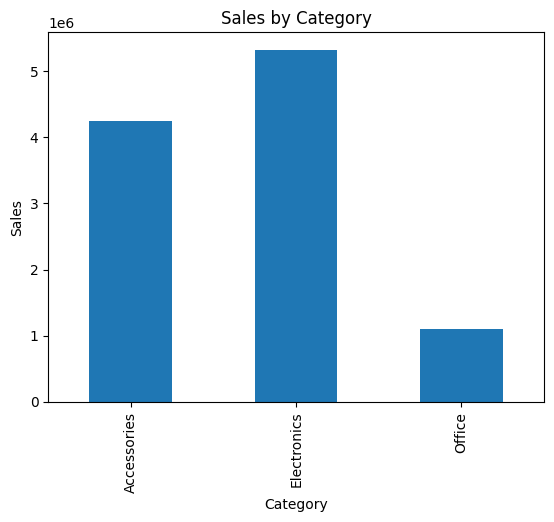

In [59]:
#create a bar chart showing sales by category
df.groupby("Category")["Sales"].sum().plot(kind="bar")
#add a title to the chart
plt.title("Sales by Category")
#add a label to the Y-axis
plt.ylabel("Sales")
#display the chart
plt.show()

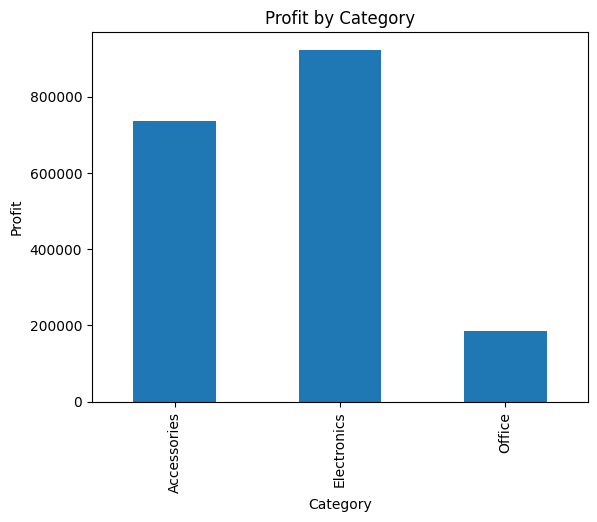

In [60]:
#create a bar chart showing profit by category
df.groupby("Category")["Profit"].sum().plot(kind="bar")
#add title to the chart
plt.title("Profit by Category")
#add a label to the chart
plt.ylabel("Profit")
#Display the chart
plt.show()

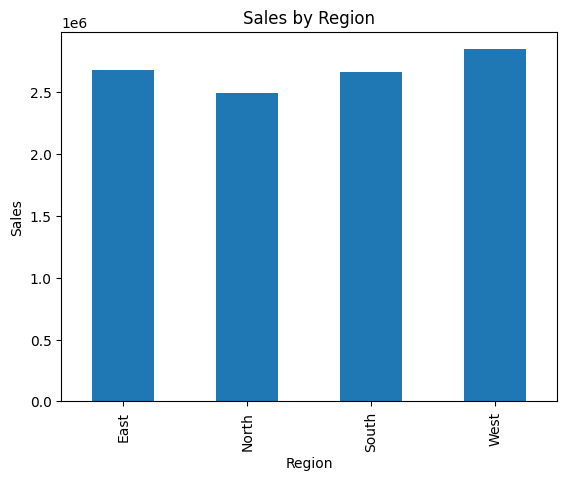

In [61]:
#create a bar chart showing profit by region
df.groupby("Region")["Sales"].sum().plot(kind="bar")
#add a title to the chart
plt.title("Sales by Region")
#add a label to the Y-axis
plt.ylabel("Sales")
#display the chart
plt.show()

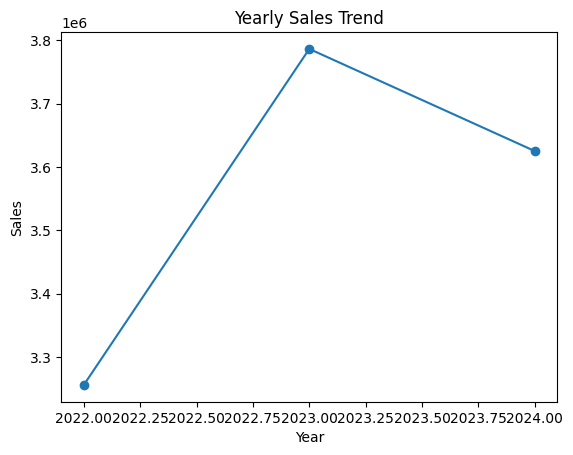

In [62]:
#create a line chart showing yearly sales
df.groupby("Year")["Sales"].sum().plot(kind="line", marker="o")
#add a title to the chart
plt.title("Yearly Sales Trend")
#add a labet to the Y-axis
plt.ylabel("Sales")
#displat the chart
plt.show()

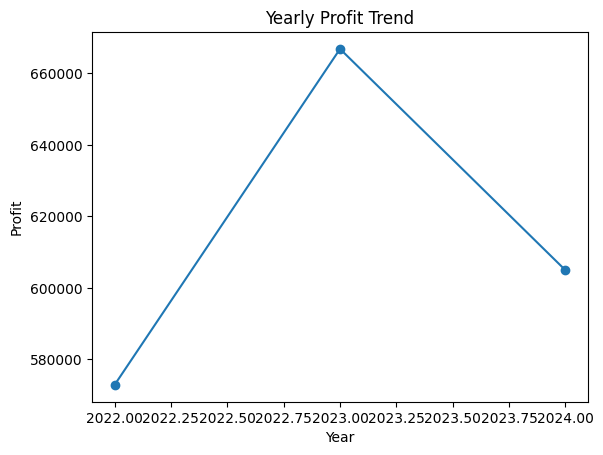

In [63]:
#create a line chart showing yearly profit
df.groupby("Year")["Profit"].sum().plot(kind="line", marker="o")
#add a title to the chart
plt.title("Yearly Profit Trend")
#add a labet to Y-axis
plt.ylabel("Profit")
#display the label
plt.show()

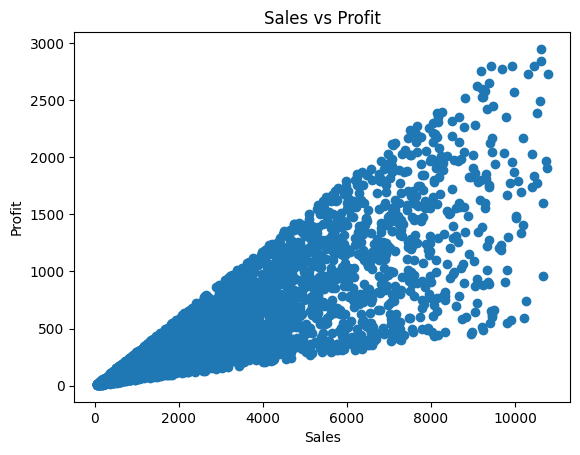

In [64]:
#create a scatter plot to examine the relationship between sales and profit
plt.scatter(df["Sales"], df["Profit"])
#add labels to the X & Y axis
plt.xlabel("Sales")
plt.ylabel("Profit")
#add title to the chart
plt.title("Sales vs Profit")
#display the chart
plt.show()

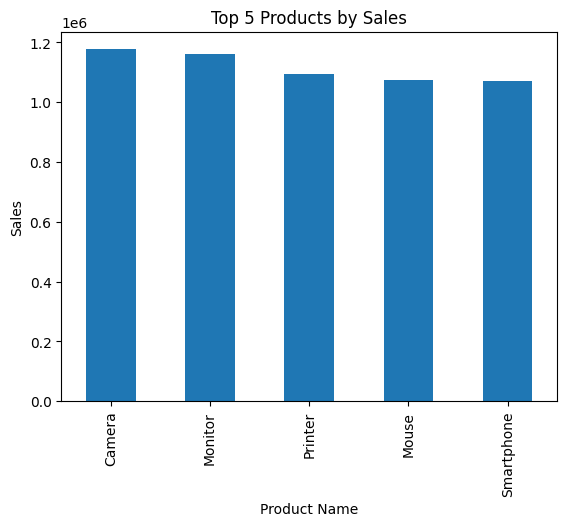

In [65]:
#crete a bar chat showing top 5 products by sales
df.groupby("Product Name")["Sales"].sum().nlargest(5).plot(kind="bar")
#add a title to the chart
plt.title("Top 5 Products by Sales")
#add a label to Y-axis
plt.ylabel("Sales")
#display the chart
plt.show()

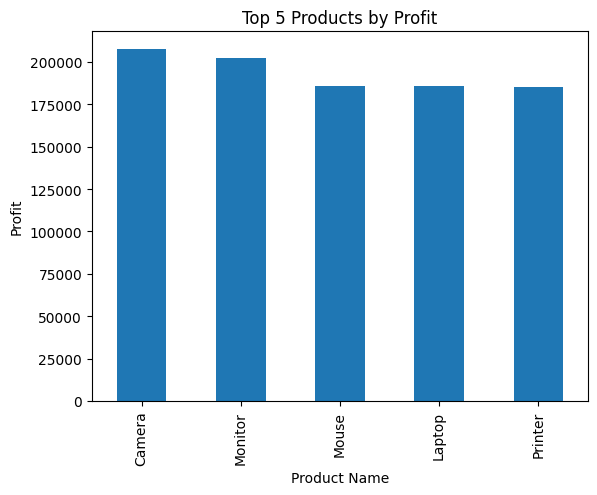

In [66]:
#create a bar chart showing the top 5 productsby profit
df.groupby("Product Name")["Profit"].sum().nlargest(5).plot(kind="bar")
#add a title to the chart
plt.title("Top 5 Products by Profit")
#add a label to the Y-label
plt.ylabel("Profit")
#display the chart
plt.show()

In [67]:
## Save the cleaned DataFrame as a CSV file
df.to_csv("ecommerce_cleaned.csv", index=False)

In [68]:
#Import the file download function from Google Colab
from google.colab import files
#Download the cleaned CSV file to the computer
files.download("/content/ecommerce_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

print(df["Order Date"].isna().sum())

print(df[df["Quantity"] <= 0])

print(df[df["Sales"] < 0])

print(df[df["Profit"] < 0])

0
Empty DataFrame
Columns: [Order Date, Product Name, Category, Region, Quantity, Sales, Profit, Year, Month, Month_Name, Quarter, Profit_Margin]
Index: []
Empty DataFrame
Columns: [Order Date, Product Name, Category, Region, Quantity, Sales, Profit, Year, Month, Month_Name, Quarter, Profit_Margin]
Index: []
Empty DataFrame
Columns: [Order Date, Product Name, Category, Region, Quantity, Sales, Profit, Year, Month, Month_Name, Quarter, Profit_Margin]
Index: []


In [70]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_transactions = len(df)

average_transaction_value = total_sales / total_transactions

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Total Quantity:", total_quantity)
print("Total Transactions:", total_transactions)
print("Average Transaction Value:", average_transaction_value)

Total Sales: 10667881
Total Profit: 1844665.21
Total Quantity: 17261
Total Transactions: 3500
Average Transaction Value: 3047.966


In [71]:
monthly_sales = (
    df.groupby(["Year", "Month", "Month_Name"])["Sales"]
    .sum()
    .reset_index()
)

monthly_sales

,Year,Month,Month_Name,Sales
0,2022,1,January,341544
1,2022,2,February,208775
2,2022,3,March,294660
3,2022,4,April,230624
4,2022,5,May,314295
5,2022,6,June,273851
6,2022,7,July,214627
7,2022,8,August,296242
8,2022,9,September,240211
9,2022,10,October,324989


In [72]:
monthly_sales = (
    df.groupby(["Year", "Month", "Month_Name"])["Sales"]
    .sum()
    .reset_index()
)

monthly_sales

,Year,Month,Month_Name,Sales
0,2022,1,January,341544
1,2022,2,February,208775
2,2022,3,March,294660
3,2022,4,April,230624
4,2022,5,May,314295
5,2022,6,June,273851
6,2022,7,July,214627
7,2022,8,August,296242
8,2022,9,September,240211
9,2022,10,October,324989


In [73]:
monthly_sales.sort_values("Sales", ascending=False).head()

,Year,Month,Month_Name,Sales
19,2023,8,August,388428
23,2023,12,December,375064
28,2024,5,May,373911
16,2023,5,May,346481
12,2023,1,January,343256


In [74]:
monthly_sales.sort_values("Sales").head()

,Year,Month,Month_Name,Sales
25,2024,2,February,179708
1,2022,2,February,208775
6,2022,7,July,214627
3,2022,4,April,230624
8,2022,9,September,240211


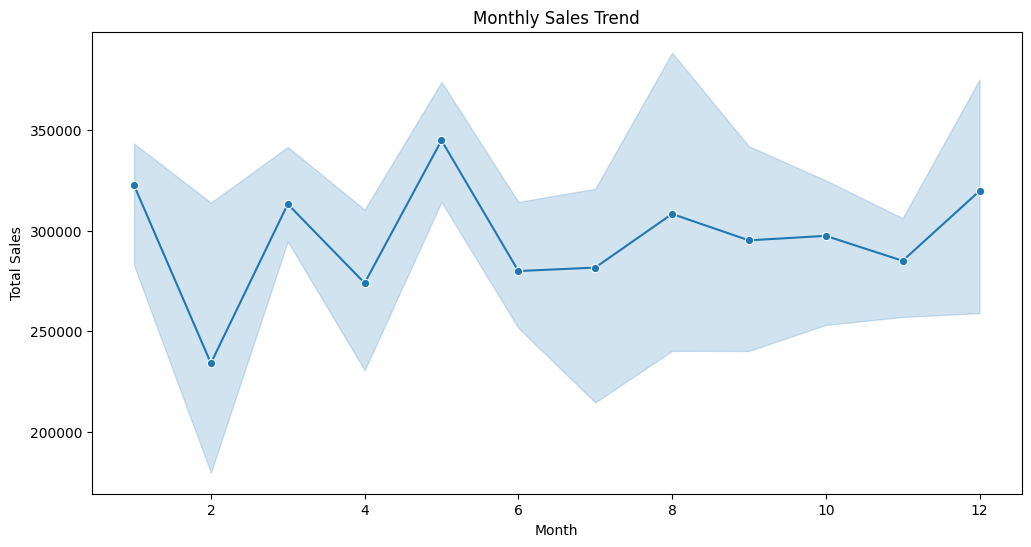

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

In [76]:
monthly_sales_year = (
    df.groupby(["Year", "Month"])["Sales"]
    .sum()
    .reset_index()
)

In [77]:
monthly_profit = (
    df.groupby(["Year", "Month"])["Profit"]
    .sum()
    .reset_index()
)

monthly_profit

,Year,Month,Profit
0,2022,1,63827.33
1,2022,2,34084.90
2,2022,3,51931.81
3,2022,4,44260.45
4,2022,5,53504.97
5,2022,6,48490.93
6,2022,7,40010.27
7,2022,8,47551.99
8,2022,9,41402.82
9,2022,10,52927.24


In [78]:
monthly_profit = (
    df.groupby(["Year", "Month"])["Profit"]
    .sum()
    .reset_index()
)

monthly_profit

,Year,Month,Profit
0,2022,1,63827.33
1,2022,2,34084.90
2,2022,3,51931.81
3,2022,4,44260.45
4,2022,5,53504.97
5,2022,6,48490.93
6,2022,7,40010.27
7,2022,8,47551.99
8,2022,9,41402.82
9,2022,10,52927.24


In [79]:
product_sales = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

product_sales.head(10)

,Sales
Product Name,
Camera,1177381
Monitor,1160048
Printer,1094216
Mouse,1074398
Smartphone,1069681
Smartwatch,1049211
Keyboard,1024507
Tablet,1023928
Laptop,1005873


In [80]:
product_sales = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

product_sales.head(10)

,Sales
Product Name,
Camera,1177381
Monitor,1160048
Printer,1094216
Mouse,1074398
Smartphone,1069681
Smartwatch,1049211
Keyboard,1024507
Tablet,1023928
Laptop,1005873


In [81]:
product_profit = (
    df.groupby("Product Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

product_profit.head(10)

,Profit
Product Name,
Camera,207630.99
Monitor,202028.17
Mouse,185763.69
Laptop,185756.81
Printer,185394.88
Smartphone,183296.97
Smartwatch,178995.81
Keyboard,175814.68
Headphones,172478.20


In [82]:
product_quantity = (
    df.groupby("Product Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

product_quantity.head(10)

,Quantity
Product Name,
Monitor,1876
Smartwatch,1807
Camera,1795
Mouse,1753
Printer,1734
Tablet,1733
Keyboard,1684
Laptop,1658
Smartphone,1617


In [83]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

,Sales
Category,
Electronics,5326074
Accessories,4247591
Office,1094216


In [84]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

,Profit
Category,
Electronics,923185.59
Accessories,736084.74
Office,185394.88


In [85]:
category_quantity = (
    df.groupby("Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

category_quantity

,Quantity
Category,
Electronics,8610
Accessories,6917
Office,1734


In [86]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

region_profit = (
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

region_quantity = (
    df.groupby("Region")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(region_sales)
print(region_profit)
print(region_quantity)

Region
West     2844450
East     2675110
South    2659548
North    2488773
Name: Sales, dtype: int64
Region
West     495358.73
East     464888.46
South    458103.27
North    426314.75
Name: Profit, dtype: float64
Region
West     4488
South    4361
East     4306
North    4106
Name: Quantity, dtype: int64


In [87]:
regional_category = (
    df.groupby(["Region", "Category"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
    .reset_index()
)

regional_category

,Region,Category,Sales,Profit,Quantity
0,East,Accessories,1032315,177839.91,1672
1,East,Electronics,1377211,239660.41,2255
2,East,Office,265584,47388.14,379
3,North,Accessories,1020641,172153.41,1704
4,North,Electronics,1244702,221585.99,2026
5,North,Office,223430,32575.35,376
6,South,Accessories,1076668,187123.37,1822
7,South,Electronics,1245527,214733.11,2039
8,South,Office,337353,56246.79,500
9,West,Accessories,1117967,198968.05,1719


In [88]:
overall_profit_margin = (
    df["Profit"].sum() / df["Sales"].sum()
) * 100

print(overall_profit_margin)

17.29176778406133


In [89]:
category_summary = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

category_summary["Profit_Margin"] = (
    category_summary["Total_Profit"] /
    category_summary["Total_Sales"]
) * 100

category_summary

,Category,Total_Sales,Total_Profit,Profit_Margin
0,Accessories,4247591,736084.74,17.329464
1,Electronics,5326074,923185.59,17.333323
2,Office,1094216,185394.88,16.943170


In [90]:
product_summary = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

product_summary["Profit_Margin"] = (
    product_summary["Total_Profit"] /
    product_summary["Total_Sales"]
) * 100

In [91]:
high_sales_threshold = product_summary["Total_Sales"].median()

low_margin_threshold = product_summary["Profit_Margin"].median()

high_sales_low_profit = product_summary[
    (product_summary["Total_Sales"] > high_sales_threshold) &
    (product_summary["Profit_Margin"] < low_margin_threshold)
]

high_sales_low_profit

,Product Name,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
6,Printer,1094216,185394.88,1734,16.943170
7,Smartphone,1069681,183296.97,1617,17.135667


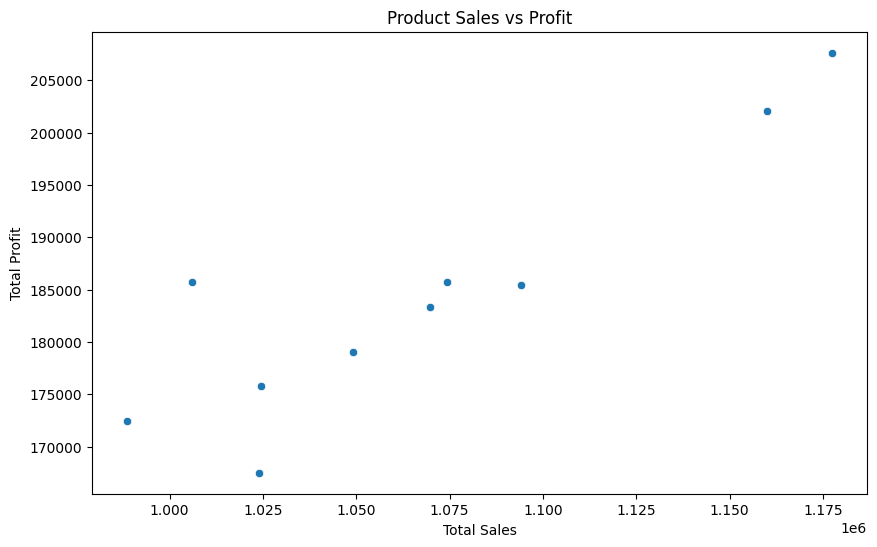

In [92]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=product_summary,
    x="Total_Sales",
    y="Total_Profit"
)

plt.title("Product Sales vs Profit")
plt.xlabel("Total Sales")
plt.ylabel("Total Profit")

plt.show()

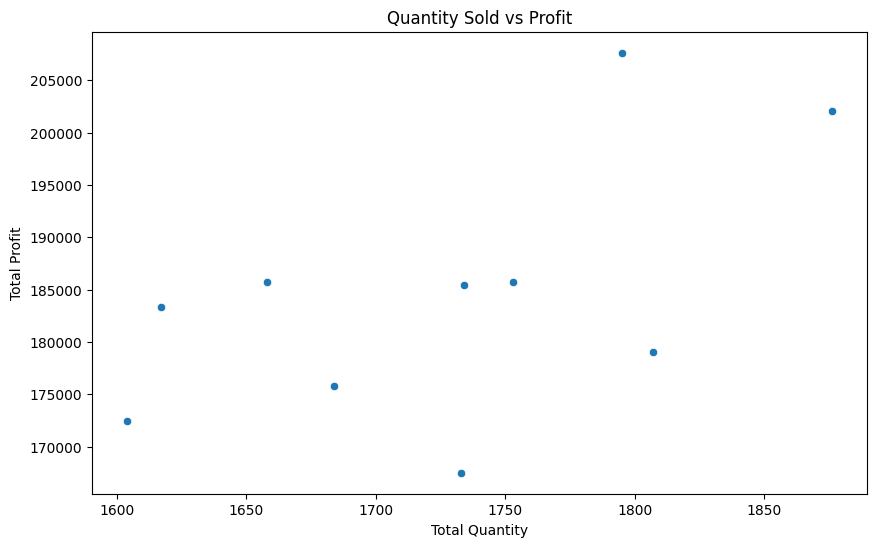

In [93]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=product_summary,
    x="Total_Quantity",
    y="Total_Profit"
)

plt.title("Quantity Sold vs Profit")
plt.xlabel("Total Quantity")
plt.ylabel("Total Profit")

plt.show()

In [94]:
print(df["Sales"].describe())
print(df["Profit"].describe())
print(df["Quantity"].describe())

count     3500.000000
mean      3047.966000
std       2440.213237
min         51.000000
25%       1049.500000
50%       2350.500000
75%       4537.000000
max      10782.000000
Name: Sales, dtype: float64
count    3500.000000
mean      527.047203
std       504.139732
min         6.970000
25%       158.695000
50%       361.070000
75%       729.125000
max      2946.930000
Name: Profit, dtype: float64
count    3500.000000
mean        4.931714
std         2.575895
min         1.000000
25%         3.000000
50%         5.000000
75%         7.000000
max         9.000000
Name: Quantity, dtype: float64


In [95]:
correlation = df[["Quantity", "Sales", "Profit"]].corr()

print(correlation)

          Quantity     Sales    Profit
Quantity  1.000000  0.662468  0.560651
Sales     0.662468  1.000000  0.832826
Profit    0.560651  0.832826  1.000000


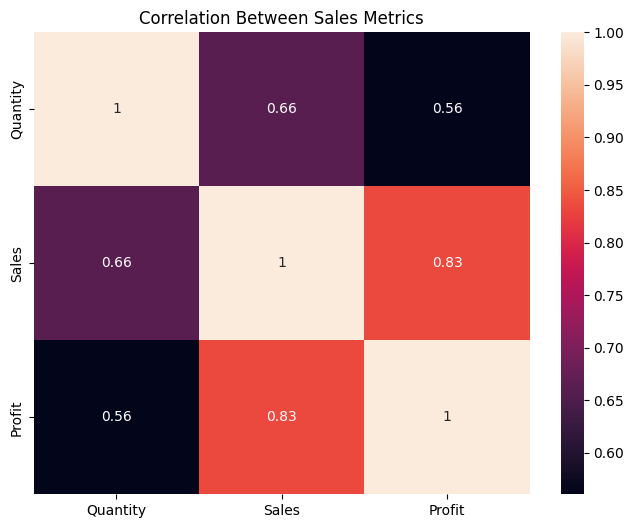

In [96]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True
)

plt.title("Correlation Between Sales Metrics")
plt.show()

In [97]:
df.to_excel("ecommerce_analysis.xlsx", index=False)

In [98]:
from google.colab import files

files.download("ecommerce_analysis.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>